# 11 — Model comparison diagnostics

Diagnostics for the Bayesian spectral-model comparison in `model_comparison/` (power law,
curved power law, moment expansion, fitted with UltraNest per TRIS ring sample on the TOD
route). Nothing here edits that module or reruns the full comparison.

* **Part 1** (always runs) reads only `model_comparison/results/evidence_per_unit_tod.csv`
  and looks at the **per-sample** log-evidence differences. No summed ln Z totals are shown:
  neighbouring ring samples are 3° apart under a ~20° beam, so they are strongly correlated
  and a sum would overstate the evidence.
* **Part 2** (`RUN_RERUNS`, off by default) reruns the three models for a few samples to
  get what the original run did not save: posteriors, best fits and maximum likelihoods.
* **Part 3** (`RUN_PRIOR_SENSITIVITY`, off by default) reruns the curved power law with a
  narrower prior on the curvature C, to see how much its evidence depends on that prior.

Reruns use the same `config.yaml`, priors, UltraNest settings and error table
(`error_bars.csv`) as `run_comparison.py`, and are cached in
`model_comparison/diagnostic_plots/cache/`, so a cached sample is never rerun.
Every figure is shown here and saved as a PNG in `model_comparison/diagnostic_plots/`.

## Settings
All paths, sample numbers and flags. Switch a flag to `True` to run that part.

In [14]:
%matplotlib inline
import os
os.environ.setdefault("TQDM_DISABLE", "1")
import sys
import copy
import logging
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import yaml
import matplotlib.pyplot as plt
from matplotlib.gridspec import GridSpecFromSubplotSpec

REPO = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
MC_DIR = REPO / "model_comparison"
CSV_PATH = MC_DIR / "results" / "evidence_per_unit_tod.csv"
CONFIG_PATH = MC_DIR / "config.yaml"
ERRORS_CSV = MC_DIR / "error_bars.csv"
PLOT_DIR = MC_DIR / "diagnostic_plots"
CACHE_DIR = PLOT_DIR / "cache"

# ---- flags ----
RUN_RERUNS = True               # Part 2: rerun the three models for RERUN_UNITS
RUN_PRIOR_SENSITIVITY = True    # Part 3: rerun the curved power law with narrower C priors

# ---- samples (TOD-route unit = TRIS ring sample index; its RA is read from the CSV) ----
RERUN_UNITS = [0, 40, 75, 89, 100, 102]
SENS_UNITS = [0, 40, 75, 100, 102]
C_HALF_WIDTHS = [0.5, 0.2, 0.1]  # 0.5 is config.yaml's prior; the others override it here

# ---- reading the evidence ----
TIE = 1.0                        # |dlogZ| < 1: indistinguishable
STRONG = 2.0                     # |dlogZ| > 2: strong
CYG_A_RA = 299.9                 # deg
N_CURVE_SAMPLES = 1000           # posterior draws used for the model bands

PL, CURVED, MOMENT = "power law", "curved power law", "moment expansion (order 2)"
SHORT = {PL: "power law", CURVED: "curved PL", MOMENT: "moment (2nd order)"}
# Okabe-Ito, colourblind-safe
COL = {PL: "#0072B2", CURVED: "#D55E00", MOMENT: "#009E73"}
UNIT_COLS = ["#0072B2", "#E69F00", "#009E73", "#CC79A7", "#56B4E9", "#D55E00"]
# 5-class diverging (PuOr, colourblind-safe), grey midpoint
CLASS_COLS = ["#542788", "#998ec3", "#d9d9d9", "#f1a340", "#b35806"]
POINT_NAMES = {"TRIS_600": "TRIS 600", "TRIS_820": "TRIS 820", "LWA_35MHz.fits": "LWA 35",
               "MAIPU_45mhZ.fits": "Maipu 45", "LWA_80MHz.fits": "LWA 80",
               "STOCKERT_VILLA_1400MHZ.fits": "Stockert 1420"}

plt.rcParams.update({"figure.dpi": 110, "font.size": 12, "axes.titlesize": 13,
                     "axes.labelsize": 12, "legend.fontsize": 10, "figure.facecolor": "white"})
PLOT_DIR.mkdir(exist_ok=True)

def save(fig, name):
    """Save a figure as PNG in PLOT_DIR, then show it inline."""
    fig.savefig(PLOT_DIR / f"{name}.png", dpi=150, bbox_inches="tight")
    plt.show()
    print(f"saved {(PLOT_DIR / f'{name}.png').relative_to(REPO)}")

# Part 1 — per-sample evidence from the saved CSV

In [15]:
ev = pd.read_csv(CSV_PATH).sort_values("ra_deg").reset_index(drop=True)
lz = {m: ev[f"logZ {m}"].to_numpy() for m in (PL, CURVED, MOMENT)}
lze = {m: ev[f"logZerr {m}"].to_numpy() for m in (PL, CURVED, MOMENT)}
ra = ev["ra_deg"].to_numpy()
RA_OF = dict(zip(ev["unit"], ev["ra_deg"]))

def diff(a, b):
    return lz[a] - lz[b], np.hypot(lze[a], lze[b])

dC, dC_err = diff(CURVED, PL)       # curved - power law
dM, dM_err = diff(MOMENT, PL)       # moment - power law
dMC, dMC_err = diff(MOMENT, CURVED) # moment - curved

print(f"{CSV_PATH.relative_to(REPO)}: {len(ev)} ring samples, RA {ra.min():.0f}-{ra.max():.0f} deg")
print(f"points per sample: {sorted(ev['n_points'].unique())}")
print(f"ln Z error per sample (median): " + ", ".join(f"{SHORT[m]} {np.median(lze[m]):.2f}" for m in lz))
print(f"error on a difference (median): dC {np.median(dC_err):.2f}, dM {np.median(dM_err):.2f}")

model_comparison/results/evidence_per_unit_tod.csv: 120 ring samples, RA 0-357 deg
points per sample: [np.int64(6)]
ln Z error per sample (median): power law 0.26, curved PL 0.27, moment (2nd order) 0.27
error on a difference (median): dC 0.37, dM 0.38


### Figure 1 — evidence difference along the ring
Each point is one TRIS ring sample: above zero the extra-parameter model has more evidence than the
power law, below zero the power law wins. The grey band (|ΔlnZ| < 1) means the two cannot be told
apart, the faint lines at ±2 mark strong preference, and the dotted line is Cygnus A.

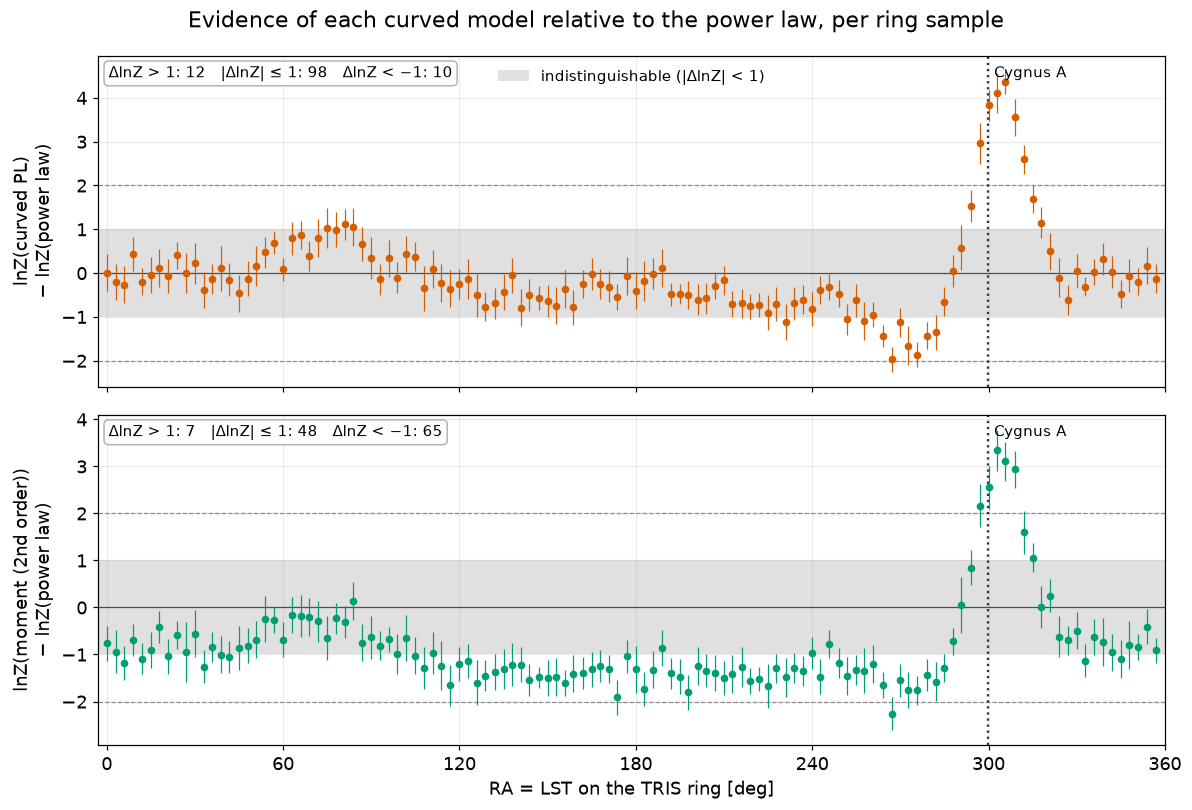

saved model_comparison/diagnostic_plots/fig1_dlogZ_vs_ra.png


In [16]:
def counts3(d):
    return int((d > TIE).sum()), int((np.abs(d) <= TIE).sum()), int((d < -TIE).sum())

fig, axes = plt.subplots(2, 1, figsize=(11, 7.5), sharex=True)
for ax, d, e, m in zip(axes, (dC, dM), (dC_err, dM_err), (CURVED, MOMENT)):
    ax.axhspan(-TIE, TIE, color="0.88", lw=0, label="indistinguishable (|ΔlnZ| < 1)")
    for y in (-STRONG, STRONG):
        ax.axhline(y, color="0.55", lw=0.8, ls="--")
    ax.axhline(0, color="0.3", lw=0.8)
    ax.errorbar(ra, d, yerr=e, fmt="o", ms=4, color=COL[m], ecolor=COL[m], elinewidth=0.8, capsize=0)
    ax.axvline(CYG_A_RA, color="0.2", ls=":", lw=1.5)
    ax.text(CYG_A_RA + 2, 0.97, "Cygnus A", transform=ax.get_xaxis_transform(), va="top", fontsize=10)
    up, tie, down = counts3(d)
    ax.text(0.01, 0.97, f"ΔlnZ > 1: {up}   |ΔlnZ| ≤ 1: {tie}   ΔlnZ < −1: {down}",
            transform=ax.transAxes, va="top", fontsize=10,
            bbox=dict(fc="white", ec="0.7", boxstyle="round,pad=0.3"))
    ax.set_ylabel(f"lnZ({SHORT[m]})\n− lnZ(power law)")
    ax.grid(alpha=0.25)
axes[0].legend(loc="upper center", frameon=False)
axes[1].set_xlabel("RA = LST on the TRIS ring [deg]")
axes[1].set_xlim(-3, 360); axes[1].set_xticks(np.arange(0, 361, 60))
fig.suptitle("Evidence of each curved model relative to the power law, per ring sample")
fig.tight_layout()
save(fig, "fig1_dlogZ_vs_ra")

### Figure 2 — absolute log-evidence along the ring
The three models' ln Z for every ring sample on one axis. The overall level follows how well the
data constrain each sample (mostly the error-bar normalisation), so read the gaps between the
lines, not their height.

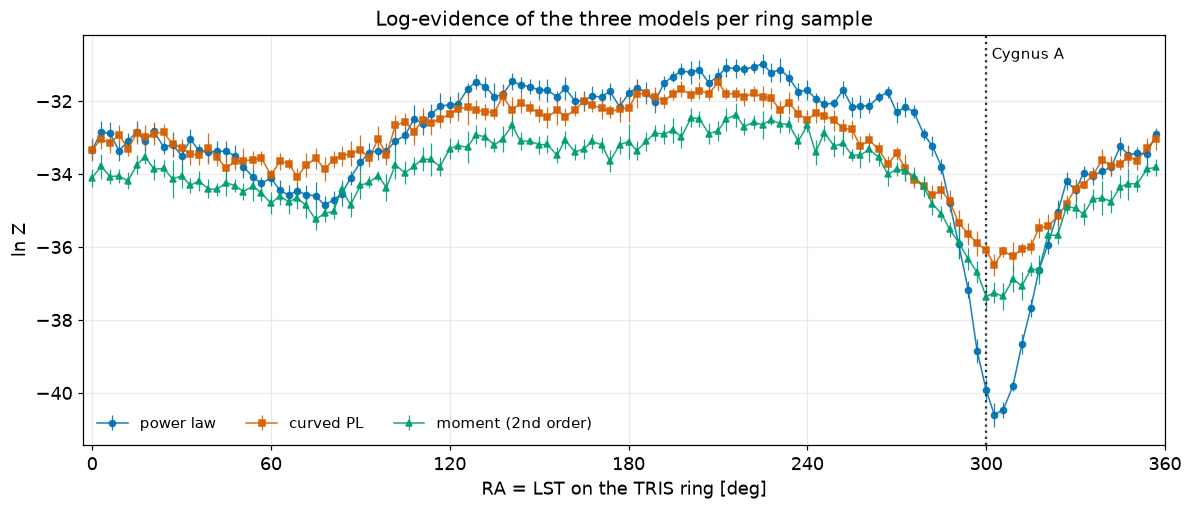

saved model_comparison/diagnostic_plots/fig2_logZ_vs_ra.png


In [17]:
fig, ax = plt.subplots(figsize=(11, 4.8))
for m, mk in zip((PL, CURVED, MOMENT), ("o", "s", "^")):
    ax.errorbar(ra, lz[m], yerr=lze[m], fmt=mk + "-", ms=4, lw=1, color=COL[m], label=SHORT[m],
                elinewidth=0.8, alpha=0.9)
ax.axvline(CYG_A_RA, color="0.2", ls=":", lw=1.5)
ax.text(CYG_A_RA + 2, 0.97, "Cygnus A", transform=ax.get_xaxis_transform(), va="top", fontsize=10)
ax.set_xlabel("RA = LST on the TRIS ring [deg]"); ax.set_ylabel("ln Z")
ax.set_xlim(-3, 360); ax.set_xticks(np.arange(0, 361, 60))
ax.legend(frameon=False, ncol=3, loc="lower left"); ax.grid(alpha=0.25)
ax.set_title("Log-evidence of the three models per ring sample")
fig.tight_layout()
save(fig, "fig2_logZ_vs_ra")

### Figure 3 — distribution of the evidence differences
Histograms of ΔlnZ over the 120 ring samples, for the curved power law and the moment expansion
against the power law. The grey band is the indistinguishable range, the solid line is zero and
the dashed line the median.

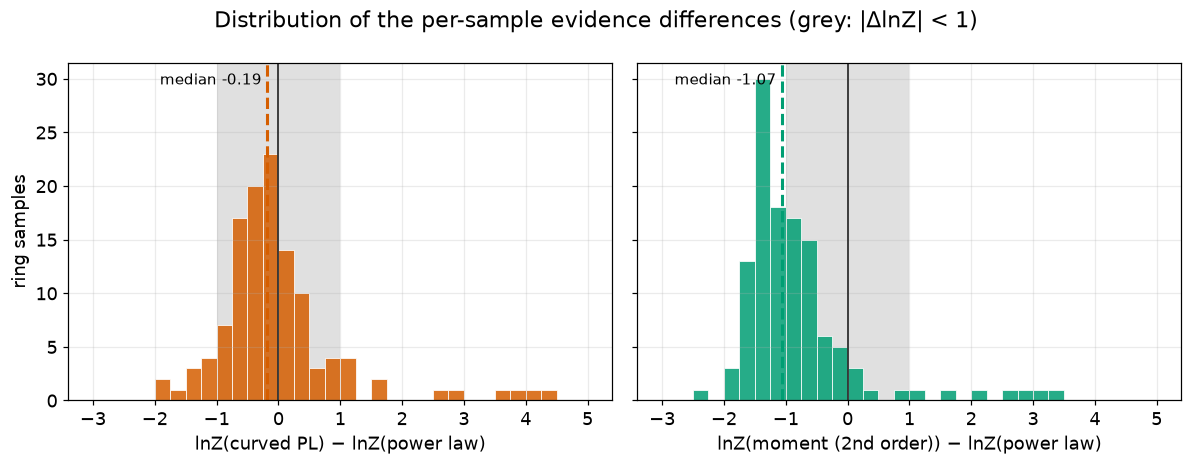

saved model_comparison/diagnostic_plots/fig3_dlogZ_histograms.png


In [18]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.3), sharey=True)
lo = np.floor(min(dC.min(), dM.min())); hi = np.ceil(max(dC.max(), dM.max()))
bins = np.arange(lo, hi + 0.25, 0.25)
for ax, d, m in zip(axes, (dC, dM), (CURVED, MOMENT)):
    ax.axvspan(-TIE, TIE, color="0.88", lw=0)
    ax.hist(d, bins=bins, color=COL[m], alpha=0.85, edgecolor="white", linewidth=0.6)
    ax.axvline(0, color="0.2", lw=1.2)
    med = np.median(d)
    ax.axvline(med, color=COL[m], lw=2, ls="--")
    ax.text(med, 0.97, f" median {med:+.2f} ", transform=ax.get_xaxis_transform(), va="top",
            ha="right" if med < 0 else "left", fontsize=10)
    ax.set_xlabel(f"lnZ({SHORT[m]}) − lnZ(power law)")
    ax.grid(alpha=0.25)
axes[0].set_ylabel("ring samples")
fig.suptitle("Distribution of the per-sample evidence differences (grey: |ΔlnZ| < 1)")
fig.tight_layout()
save(fig, "fig3_dlogZ_histograms")

### Figure 4 — how often each model is preferred
For each pair (A vs B) the bar splits the 120 ring samples by ΔlnZ = lnZ(A) − lnZ(B): purple means A
is favoured, orange that B is, and grey that they cannot be told apart. Read the bar's colour balance;
the numbers are sample counts.

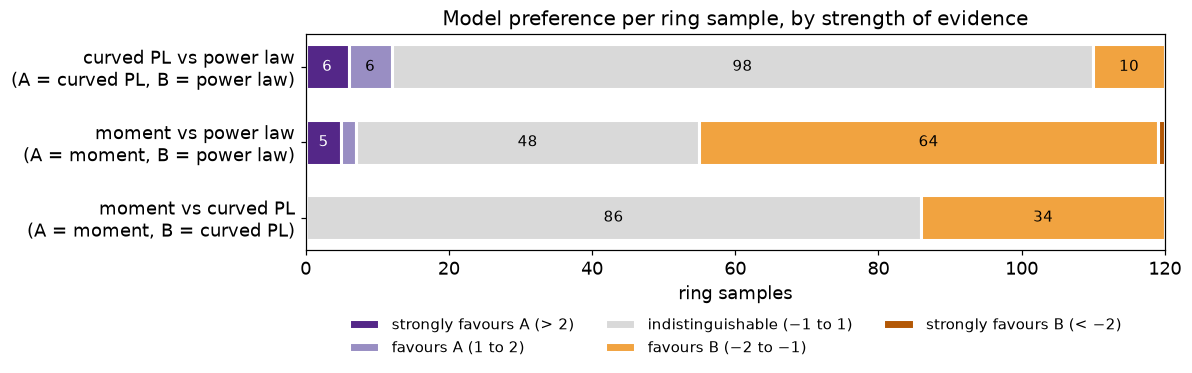

saved model_comparison/diagnostic_plots/fig4_preference_counts.png
                        strongly favours A (> 2)  favours A (1 to 2)  indistinguishable (−1 to 1)  favours B (−2 to −1)  strongly favours B (< −2)
curved PL vs power law                         6                   6                           98                    10                          0
moment vs power law                            5                   2                           48                    64                          1
moment vs curved PL                            0                   0                           86                    34                          0


In [19]:
CLASSES = [("strongly favours A (> 2)", lambda d: d > STRONG),
           ("favours A (1 to 2)", lambda d: (d > TIE) & (d <= STRONG)),
           ("indistinguishable (−1 to 1)", lambda d: np.abs(d) <= TIE),
           ("favours B (−2 to −1)", lambda d: (d < -TIE) & (d >= -STRONG)),
           ("strongly favours B (< −2)", lambda d: d < -STRONG)]
PAIRS = [("curved PL vs power law", dC), ("moment vs power law", dM), ("moment vs curved PL", dMC)]
table = pd.DataFrame({lab: [int(f(d).sum()) for _, d in PAIRS] for lab, f in CLASSES},
                     index=[p for p, _ in PAIRS])
assert (table.sum(axis=1) == len(ev)).all()

fig, ax = plt.subplots(figsize=(11, 3.8))
y = np.arange(len(PAIRS))[::-1]
left = np.zeros(len(PAIRS))
for (lab, _), c in zip(CLASSES, CLASS_COLS):
    w = table[lab].to_numpy()
    ax.barh(y, w, left=left, color=c, edgecolor="white", linewidth=2, height=0.6, label=lab)
    for yi, li, wi in zip(y, left, w):
        if wi >= 4:
            ax.text(li + wi / 2, yi, str(wi), ha="center", va="center", fontsize=10,
                    color="white" if c in (CLASS_COLS[0], CLASS_COLS[4]) else "black")
    left += w
ax.set_yticks(y); ax.set_yticklabels([f"{p}\n(A = {p.split(' vs ')[0]}, B = {p.split(' vs ')[1]})" for p, _ in PAIRS])
ax.set_xlim(0, len(ev)); ax.set_xlabel("ring samples")
ax.legend(ncol=3, loc="upper center", bbox_to_anchor=(0.5, -0.25), frameon=False)
ax.set_title("Model preference per ring sample, by strength of evidence")
fig.tight_layout()
save(fig, "fig4_preference_counts")
print(table.to_string())

# Part 2 — posteriors, best fits and maximum likelihood (reruns)

**What the original run saved.** `run_comparison.py` writes, per sample, only the sample index,
RA, number of points, the inputs used, and ln Z ± error for each model. It keeps no best-fit
parameters, no maximum log-likelihood and no posterior samples, and `sampler.log_dir` is `null`, so
UltraNest wrote nothing to disk. The next cell checks this, and then (only if `RUN_RERUNS = True`)
reruns the three models for `RERUN_UNITS` and caches each result.

In [20]:
with open(CONFIG_PATH) as f:
    cfg = yaml.safe_load(f)
saved_cols = list(ev.columns)
log_dir = cfg["sampler"].get("log_dir")
sample_files = (sorted(Path(log_dir).rglob("equal_weighted_post.txt")) if log_dir and Path(log_dir).exists() else [])
extra = [c for c in saved_cols if not c.startswith(("logZ ", "logZerr "))]
print("columns saved per sample:", ", ".join(extra), "+ logZ and logZerr per model")
print("best-fit parameters saved:   ", any("best" in c or "beta" in c for c in saved_cols))
print("max log-likelihood saved:    ", any("logl" in c.lower() or "maxl" in c.lower() for c in saved_cols))
print(f"posterior samples on disk:    {bool(sample_files)}  (sampler.log_dir = {log_dir!r})")
POSTERIORS_SAVED = bool(sample_files)
if POSTERIORS_SAVED:
    print("Posterior files found: NOTE run_comparison reuses one log_dir for every sample and model, "
          "so only the last run's files survive. Not used here.")

columns saved per sample: unit, ra_deg, n_points, inputs + logZ and logZerr per model
best-fit parameters saved:    False
max log-likelihood saved:     False
posterior samples on disk:    False  (sampler.log_dir = None)


In [21]:
sys.dont_write_bytecode = True                   # leave no __pycache__ in model_comparison/
sys.path.insert(0, str(REPO / "src"))
sys.path.insert(0, str(MC_DIR))
from models import build_models, prior_transform
import run_comparison as rc                      # imported for its data helpers; main() is not run

MODELS = build_models(cfg)
assert list(MODELS) == [PL, CURVED, MOMENT], list(MODELS)
SCFG = cfg["sampler"]
# Moment expansion: beta fixed at config.yaml's models.moment_beta_fixed (omega1 free), or free if null.
BETA_FIX = cfg["models"].get("moment_beta_fixed")
TAG = {PL: "base", CURVED: "base", MOMENT: "base" if BETA_FIX is None else f"beta{float(BETA_FIX):g}"}
print("moment expansion:", "beta free, omega1 = 0" if BETA_FIX is None else f"beta fixed at {float(BETA_FIX):g}, omega1 free")
assert cfg["priors"]["C"]["type"] == "uniform" and -cfg["priors"]["C"]["low"] == cfg["priors"]["C"]["high"] == 0.5

def slug(s):
    return "".join(ch if ch.isalnum() else "_" for ch in s).strip("_")

def cache_path(unit, model, tag):
    return CACHE_DIR / f"unit{unit:03d}__{slug(model)}__{tag}.npz"

_INP = None
def get_inputs():
    """The TOD-route inputs (built once, takes a few minutes)."""
    global _INP
    if _INP is None:
        from moonrunes.config import load_config
        from moonrunes.sed_prototype import Inputs
        print("building the TOD-route inputs (takes a few minutes)...")
        _INP = Inputs(load_config(REPO / "configs" / "run_config.yaml"), REPO / "res",
                      target_file=cfg["data"]["target_file"], verbose=False)
    return _INP

_POINTS = {}
def unit_points(units):
    """(nu, t, s, keys) per unit, built exactly as run_comparison does (TOD route)."""
    need = [u for u in units if u not in _POINTS]
    if need:
        errors = rc.read_error_bars(ERRORS_CSV)
        inp = get_inputs()
        for uid, _, pts in rc.tod_units(inp, errors):
            if uid in need:
                pts = rc.usable(pts)
                _POINTS[uid] = (np.array([q[1] for q in pts]), np.array([q[2] for q in pts]),
                                np.array([q[3] for q in pts]), [q[0] for q in pts])
    return {u: _POINTS[u] for u in units}

def run_nested(model, priors, nu, t, s):
    """The same likelihood and UltraNest call as rc.log_evidence, keeping the posterior."""
    import ultranest
    names, fn = MODELS[model]
    transform = prior_transform(names, priors)
    norm = -np.sum(np.log(s * np.sqrt(2 * np.pi)))
    def loglike(params):
        r = (t - fn(nu, params)) / s
        return -0.5 * np.sum(r * r, axis=-1) + norm
    sampler = ultranest.ReactiveNestedSampler(names, loglike, transform, vectorized=True,
                                              log_dir=SCFG.get("log_dir"))
    logging.getLogger("ultranest").setLevel(logging.WARNING)
    res = sampler.run(min_num_live_points=int(SCFG["min_num_live_points"]), dlogz=float(SCFG["dlogz"]),
                      show_status=False, viz_callback=False)
    return dict(logz=res["logz"], logzerr=res["logzerr"], samples=res["samples"],
                maxlogl=res["maximum_likelihood"]["logl"], maxpoint=np.asarray(res["maximum_likelihood"]["point"]),
                names=np.array(names))

def get_results(units, model, tag, priors, allow_run):
    """{unit: result} from the cache; missing ones are run only if allow_run."""
    out, missing = {}, []
    for u in units:
        p = cache_path(u, model, tag)
        if p.exists():
            z = np.load(p, allow_pickle=False)
            out[u] = {k: z[k] for k in z.files}
        else:
            missing.append(u)
    if missing and allow_run:
        CACHE_DIR.mkdir(parents=True, exist_ok=True)
        logging.getLogger("ultranest").setLevel(logging.WARNING)
        for u, (nu, t, s, keys) in unit_points(missing).items():
            r = run_nested(model, priors, nu, t, s)
            r.update(nu=nu, t=t, s=s, keys=np.array(keys), unit=u, tag=tag)
            np.savez(cache_path(u, model, tag), **r)
            out[u] = r
            print(f"  ran unit {u:3d}, {SHORT[model]:<20} [{tag}]  lnZ = {r['logz']:.2f} ± {r['logzerr']:.2f}")
    return out

HASLAM_CACHE = CACHE_DIR / "haslam_tod.npz"
def haslam_points(allow_run):
    """Haslam (the target map, NOT a fit point) through the TRIS beam, per ring sample, for plotting only."""
    if HASLAM_CACHE.exists():
        z = np.load(HASLAM_CACHE, allow_pickle=False)
        return {k: z[k] for k in z.files}
    if not allow_run:
        return None
    from moonrunes.sky_maps import rj_excess
    from moonrunes.sed_prototype import sigma_for
    inp = get_inputs(); m = inp.target; d = inp.tods[m["name"]]
    t = np.array([float(rj_excess(v, m)) for v in d["tod"]])
    out = dict(nu=float(m["freq_mhz"]), t=t, s=np.asarray(sigma_for(m, t), dtype=float),
               good=np.asarray(d["good"], dtype=bool), file=str(m["file"]))
    CACHE_DIR.mkdir(parents=True, exist_ok=True)
    np.savez(HASLAM_CACHE, **out)
    return out

P2 = {m: get_results(RERUN_UNITS, m, TAG[m], cfg["priors"], RUN_RERUNS) for m in MODELS}
HAS = haslam_points(RUN_RERUNS)
P2_UNITS = [u for u in RERUN_UNITS if all(u in P2[m] for m in MODELS)]
if not P2_UNITS:
    print("PART 2 SKIPPED: no cached reruns found and RUN_RERUNS = False. "
          "Set RUN_RERUNS = True in the settings cell to rerun units", RERUN_UNITS)
else:
    print(f"Part 2 results available for units {P2_UNITS}"
          + ("" if len(P2_UNITS) == len(RERUN_UNITS) else f" (missing: {sorted(set(RERUN_UNITS) - set(P2_UNITS))})"))
    print("\nrerun lnZ against the saved CSV (UltraNest is not seeded, so expect agreement within the errors):")
    for u in P2_UNITS:
        row = ev.set_index("unit").loc[u]
        print(f"  unit {u:3d}: " + "   ".join(
            f"{SHORT[m]} {float(P2[m][u]['logz']):+.2f} vs {row[f'logZ {m}']:+.2f}" for m in MODELS))

Part 2 results available for units [0, 40, 75, 89, 100, 102]

rerun lnZ against the saved CSV (UltraNest is not seeded, so expect agreement within the errors):
  unit   0: power law -33.31 vs -33.34   curved PL -33.11 vs -33.33   moment (2nd order) -34.02 vs -34.11
  unit  40: power law -32.06 vs -32.10   curved PL -32.60 vs -32.35   moment (2nd order) -33.43 vs -33.30
  unit  75: power law -31.55 vs -30.98   curved PL -32.00 vs -31.88   moment (2nd order) -32.87 vs -32.65
  unit  89: power law -32.01 vs -31.76   curved PL -33.64 vs -33.72   moment (2nd order) -33.70 vs -34.01
  unit 100: power law -39.92 vs -39.92   curved PL -35.90 vs -36.09   moment (2nd order) -37.06 vs -37.36
  unit 102: power law -40.32 vs -40.46   curved PL -36.08 vs -36.11   moment (2nd order) -37.25 vs -37.36


### Figure 5 — data and fitted models for the rerun samples
Each panel is one ring sample: the six SED points (CMB-free Rayleigh–Jeans temperature) with their
error bars, and each model's posterior median with its 68% band (none for the curved power law).
Haslam 408 MHz (open diamond) is plotted for comparison only and is not used in any fit. The small panel below shows the
residuals, data minus model in units of σ, for the power law and the curved power law.

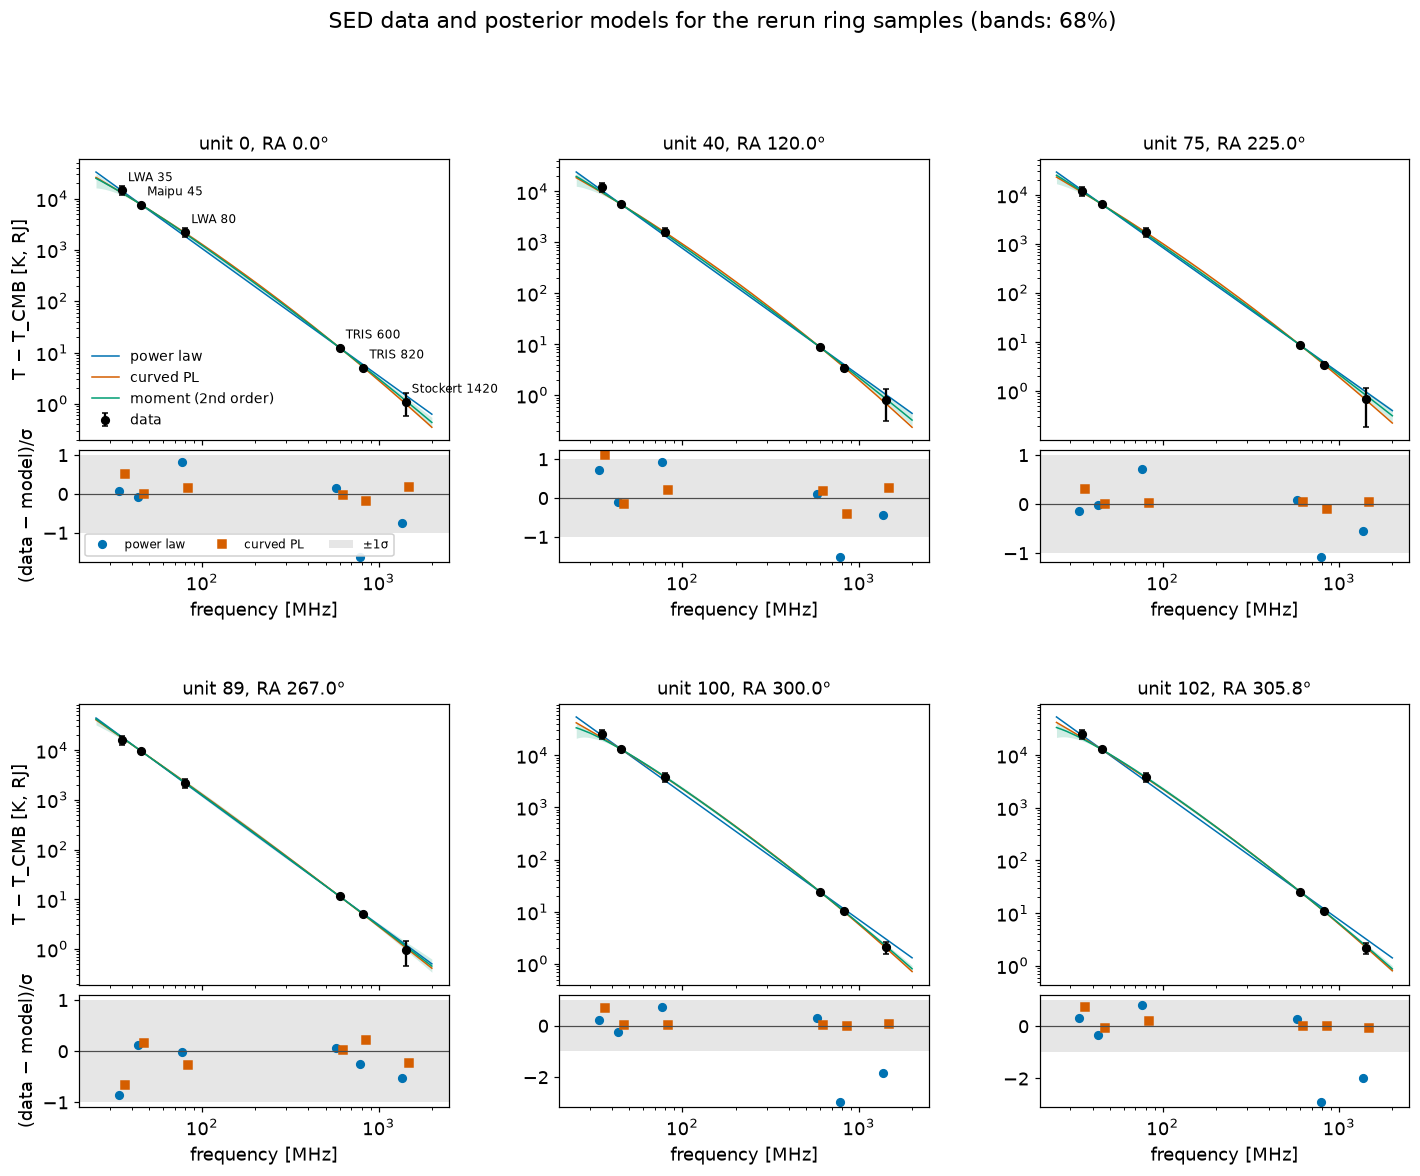

saved model_comparison/diagnostic_plots/fig5_sed_fits_per_unit.png


In [22]:
def model_band(model, samples, nu):
    names, fn = MODELS[model]
    rng = np.random.default_rng(0)
    sel = samples if len(samples) <= N_CURVE_SAMPLES else samples[rng.choice(len(samples), N_CURVE_SAMPLES, replace=False)]
    curves = fn(nu, sel)
    return np.percentile(curves, [16, 50, 84], axis=0)

if not P2_UNITS:
    print("Figure 5 skipped: no Part 2 results (set RUN_RERUNS = True).")
else:
    ncol = 3; nrow = int(np.ceil(len(P2_UNITS) / ncol))
    fig = plt.figure(figsize=(5.2 * ncol, 5.6 * nrow))
    outer = fig.add_gridspec(nrow, ncol, hspace=0.35, wspace=0.3)
    grid = np.geomspace(25, 2000, 200)
    for i, u in enumerate(P2_UNITS):
        g = GridSpecFromSubplotSpec(2, 1, subplot_spec=outer[i // ncol, i % ncol], height_ratios=[3, 1.2], hspace=0.05)
        ax = fig.add_subplot(g[0]); axr = fig.add_subplot(g[1], sharex=ax)
        r0 = P2[PL][u]; nu, t, s, keys = r0["nu"], r0["t"], r0["s"], [str(k) for k in r0["keys"]]
        for m in MODELS:
            lo_, med_, hi_ = model_band(m, P2[m][u]["samples"], grid)
            if m != CURVED:   # no band for the curved power law
                ax.fill_between(grid, lo_, hi_, color=COL[m], alpha=0.18, lw=0)
            ax.plot(grid, med_, color=COL[m], lw=1.0, label=SHORT[m])
        ax.errorbar(nu, t, yerr=s, fmt="o", color="black", ms=5, capsize=2, zorder=5, label="data")
        if HAS is not None and bool(HAS["good"][u]):   # plotted only, not in any fit
            hn, ht, hs = float(HAS["nu"]), float(HAS["t"][u]), float(HAS["s"][u])
            ax.errorbar(hn, ht, yerr=hs, fmt="D", ms=5, mfc="white", mec="black", ecolor="black",
                        capsize=2, zorder=6, label="Haslam 408 (not fitted)")
            if i == 0:
                ax.annotate("Haslam 408", (hn, ht), xytext=(4, 6), textcoords="offset points", fontsize=8)
        if i == 0:
            for n_, t_, k_ in zip(nu, t, keys):
                ax.annotate(POINT_NAMES.get(k_, k_), (n_, t_), xytext=(4, 6), textcoords="offset points", fontsize=8)
        ax.set_xscale("log"); ax.set_yscale("log")
        ax.set_title(f"unit {u}, RA {RA_OF[u]:.1f}°", fontsize=12)
        ax.tick_params(labelbottom=False); #ax.grid(alpha=0.25, which="both")
        if i % ncol == 0:
            ax.set_ylabel("T − T_CMB [K, RJ]")
        for m, off, mk in ((PL, 0.96, "o"), (CURVED, 1.04, "s")):
            _, med_at, _ = model_band(m, P2[m][u]["samples"], nu)
            axr.plot(nu * off, (t - med_at) / s, mk, color=COL[m], ms=5, label=SHORT[m])
        axr.axhspan(-1, 1, color="0.9", lw=0, label="±1σ"); axr.axhline(0, color="0.3", lw=0.8)
        if i == 0:
            axr.legend(loc="lower left", fontsize=8, ncol=3, frameon=True, framealpha=0.9)
        axr.set_xscale("log"); #axr.grid(alpha=0.25)
        if i % ncol == 0:
            axr.set_ylabel("(data − model)/σ")
        axr.set_xlabel("frequency [MHz]")
    fig.axes[0].legend(loc="lower left", fontsize=9, frameon=False)
    fig.suptitle("SED data and posterior models for the rerun ring samples (bands: 68%)", y=1.0)
    save(fig, "fig5_sed_fits_per_unit")

### Figure 6 — better fit or Occam penalty?
Left: for the curved power law and the moment expansion, how much higher their best-fit log-likelihood
is than the power law's (hatched) and how much higher their evidence is (solid); a big gain in fit
with no gain in evidence means the extra parameter is paid for by its prior. Right: each model's Occam
penalty, max lnL − lnZ, which grows with the prior volume the data rule out.

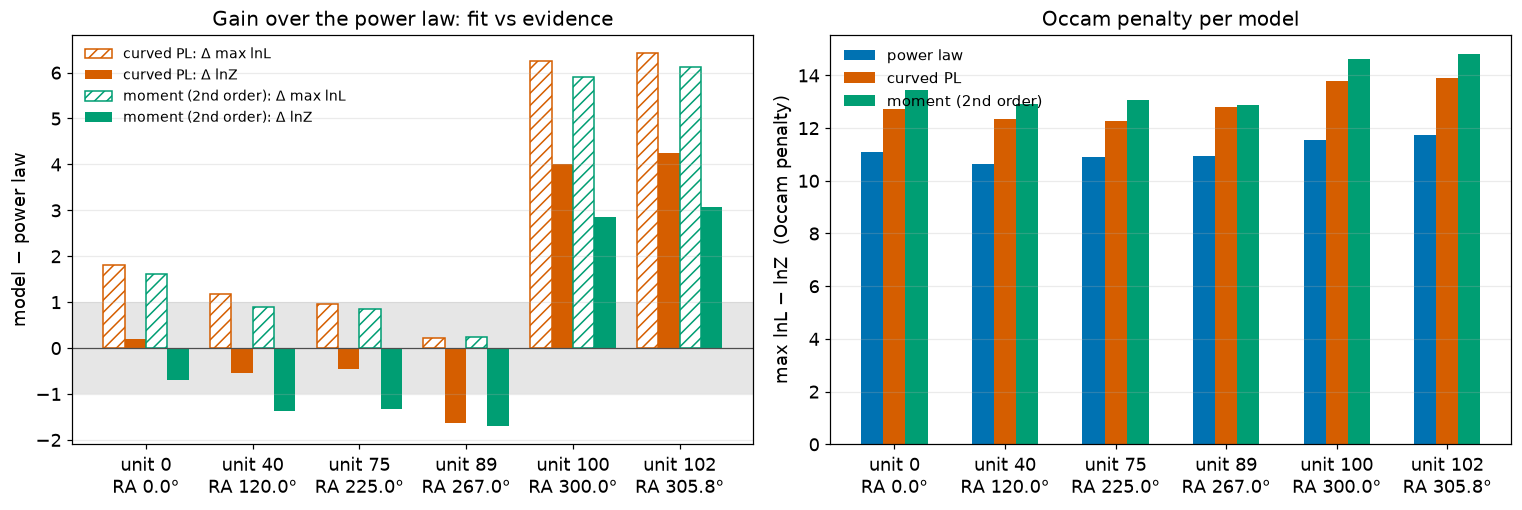

saved model_comparison/diagnostic_plots/fig6_maxlogl_vs_logZ.png
     power law max lnL  curved PL max lnL  moment (2nd order) max lnL  power law lnZ  curved PL lnZ  moment (2nd order) lnZ
0               -22.21             -20.40                      -20.59         -33.31         -33.11                  -34.02
40              -21.43             -20.26                      -20.53         -32.06         -32.60                  -33.43
75              -20.66             -19.72                      -19.82         -31.55         -32.00                  -32.87
89              -21.06             -20.84                      -20.82         -32.01         -33.64                  -33.70
100             -28.36             -22.11                      -22.46         -39.92         -35.90                  -37.06
102             -28.58             -22.16                      -22.46         -40.32         -36.08                  -37.25


In [23]:
if not P2_UNITS:
    print("Figure 6 skipped: no Part 2 results (set RUN_RERUNS = True).")
else:
    maxl = {m: np.array([float(P2[m][u]["maxlogl"]) for u in P2_UNITS]) for m in MODELS}
    lzr = {m: np.array([float(P2[m][u]["logz"]) for u in P2_UNITS]) for m in MODELS}
    x = np.arange(len(P2_UNITS)); w = 0.2
    fig, (a1, a2) = plt.subplots(1, 2, figsize=(14, 4.8))
    for j, m in enumerate((CURVED, MOMENT)):
        a1.bar(x + (2 * j - 1.5) * w, maxl[m] - maxl[PL], w, color="white", edgecolor=COL[m], hatch="///",
               label=f"{SHORT[m]}: Δ max lnL")
        a1.bar(x + (2 * j - 0.5) * w, lzr[m] - lzr[PL], w, color=COL[m], label=f"{SHORT[m]}: Δ lnZ")
    a1.axhline(0, color="0.3", lw=0.8); a1.axhspan(-TIE, TIE, color="0.9", lw=0, zorder=0)
    a1.set_xticks(x); a1.set_xticklabels([f"unit {u}\nRA {RA_OF[u]:.1f}°" for u in P2_UNITS])
    a1.set_ylabel("model − power law"); a1.legend(frameon=False, fontsize=9); a1.grid(alpha=0.25, axis="y")
    a1.set_title("Gain over the power law: fit vs evidence")
    for j, m in enumerate(MODELS):
        a2.bar(x + (j - 1) * w, maxl[m] - lzr[m], w, color=COL[m], label=SHORT[m])
    a2.set_xticks(x); a2.set_xticklabels([f"unit {u}\nRA {RA_OF[u]:.1f}°" for u in P2_UNITS])
    a2.set_ylabel("max lnL − lnZ  (Occam penalty)"); a2.legend(frameon=False); a2.grid(alpha=0.25, axis="y")
    a2.set_title("Occam penalty per model")
    fig.tight_layout()
    save(fig, "fig6_maxlogl_vs_logZ")
    print(pd.DataFrame({f"{SHORT[m]} max lnL": maxl[m] for m in MODELS} |
                       {f"{SHORT[m]} lnZ": lzr[m] for m in MODELS}, index=P2_UNITS).round(2).to_string())

### Figure 7 — posterior of the curvature C
The marginal posterior of the curved power law's curvature C for each rerun ring sample, with the
prior range shaded. A posterior that fills the prior means the data do not constrain C; one well
away from zero means real curvature.

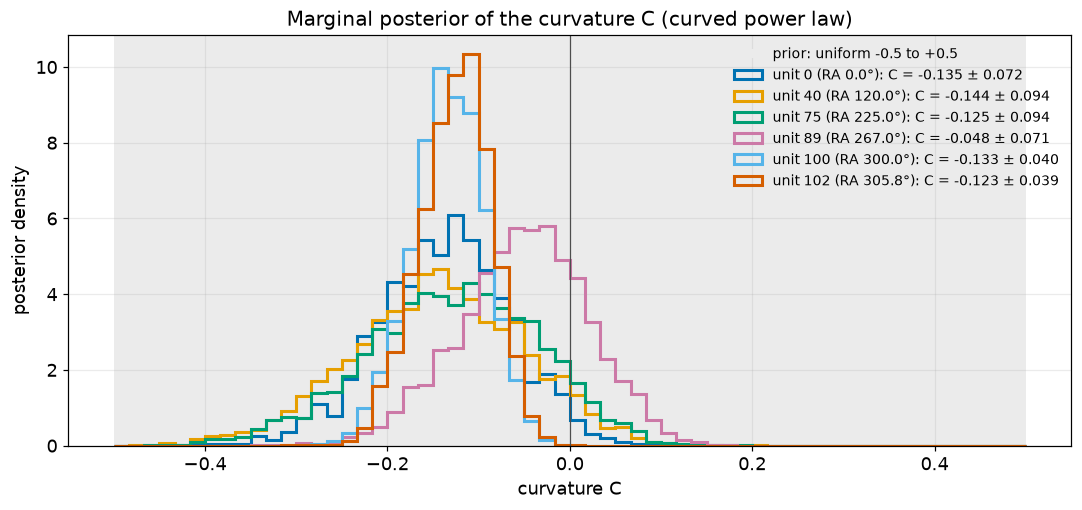

saved model_comparison/diagnostic_plots/fig7_C_posterior.png


In [24]:
if not P2_UNITS:
    print("Figure 7 skipped: no Part 2 results (set RUN_RERUNS = True).")
else:
    names = [str(n) for n in P2[CURVED][P2_UNITS[0]]["names"]]; ic = names.index("C")
    lo_c, hi_c = cfg["priors"]["C"]["low"], cfg["priors"]["C"]["high"]
    fig, ax = plt.subplots(figsize=(10, 4.8))
    ax.axvspan(lo_c, hi_c, color="0.92", lw=0, label=f"prior: uniform {lo_c:+g} to {hi_c:+g}")
    bins = np.linspace(lo_c, hi_c, 61)
    for u, c in zip(P2_UNITS, UNIT_COLS):
        smp = P2[CURVED][u]["samples"][:, ic]
        ax.hist(smp, bins=bins, density=True, histtype="step", lw=2, color=c,
                label=f"unit {u} (RA {RA_OF[u]:.1f}°): C = {np.median(smp):+.3f} ± {np.std(smp):.3f}")
    ax.axvline(0, color="0.3", lw=0.8)
    ax.set_xlim(lo_c - 0.05, hi_c + 0.05); ax.set_xlabel("curvature C"); ax.set_ylabel("posterior density")
    ax.legend(frameon=False, fontsize=9); ax.grid(alpha=0.25)
    ax.set_title("Marginal posterior of the curvature C (curved power law)")
    fig.tight_layout()
    save(fig, "fig7_C_posterior")

# Part 3 — prior sensitivity of the curvature

The curved power law is rerun with the C prior narrowed from ±0.5 (config) to ±0.2 and ±0.1. The
prior is overridden here only; `config.yaml` is not edited. The ±0.5 points and the power-law reference
are taken from Part 2's cache, and are computed only if missing.

In [25]:
P3_READY = False
if not RUN_PRIOR_SENSITIVITY and not any(cache_path(u, CURVED, f"C{w:g}").exists()
                                         for u in SENS_UNITS for w in C_HALF_WIDTHS if w != 0.5):
    print("PART 3 SKIPPED: no cached prior-sensitivity runs and RUN_PRIOR_SENSITIVITY = False. "
          "Set it to True in the settings cell to run units", SENS_UNITS)
else:
    ref = get_results(SENS_UNITS, PL, "base", cfg["priors"], RUN_PRIOR_SENSITIVITY)
    sens = {}
    for w in C_HALF_WIDTHS:
        pri = copy.deepcopy(cfg["priors"])
        pri["C"] = {"type": "uniform", "low": -w, "high": w}
        tag = "base" if w == 0.5 else f"C{w:g}"
        sens[w] = get_results(SENS_UNITS, CURVED, tag, pri, RUN_PRIOR_SENSITIVITY)
    S3_UNITS = [u for u in SENS_UNITS if u in ref and all(u in sens[w] for w in C_HALF_WIDTHS)]
    P3_READY = bool(S3_UNITS)
    if not P3_READY:
        print("Part 3: incomplete cache, nothing to plot.")

### Figure 8 — curved-model evidence against the width of the C prior
Each line is one ring sample: lnZ(curved) − lnZ(power law) as the C prior is narrowed. If the curvature
is not needed, a narrower prior raises the curved model's evidence towards the power law's; if the data
need |C| beyond the prior, it falls.

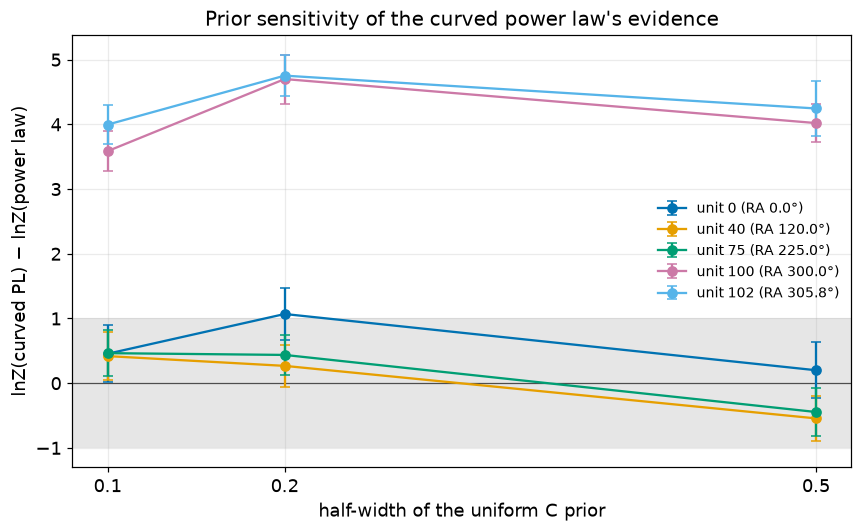

saved model_comparison/diagnostic_plots/fig8_prior_sensitivity_C.png
     C ±0.5  C ±0.2  C ±0.1
0      0.20    1.07    0.45
40    -0.55    0.27    0.42
75    -0.45    0.44    0.46
100    4.02    4.70    3.58
102    4.24    4.75    4.00

Sign of ΔlnZ flips with the prior width for: unit 40, unit 75


In [26]:
if not P3_READY:
    print("Figure 8 skipped: no Part 3 results (set RUN_PRIOR_SENSITIVITY = True).")
else:
    W = np.array(C_HALF_WIDTHS)
    fig, ax = plt.subplots(figsize=(8, 5))
    ax.axhspan(-TIE, TIE, color="0.9", lw=0); ax.axhline(0, color="0.3", lw=0.8)
    rows, flips = {}, []
    for u, c in zip(S3_UNITS, UNIT_COLS):
        d = np.array([float(sens[w][u]["logz"]) - float(ref[u]["logz"]) for w in W])
        e = np.array([np.hypot(float(sens[w][u]["logzerr"]), float(ref[u]["logzerr"])) for w in W])
        ax.errorbar(W, d, yerr=e, fmt="o-", color=c, capsize=3, label=f"unit {u} (RA {RA_OF[u]:.1f}°)")
        rows[u] = d
        if np.any(np.sign(d) != np.sign(d[0])):
            flips.append(u)
    ax.set_xlabel("half-width of the uniform C prior"); ax.set_ylabel("lnZ(curved PL) − lnZ(power law)")
    ax.set_xticks(W); ax.legend(frameon=False, fontsize=9); ax.grid(alpha=0.25)
    ax.set_title("Prior sensitivity of the curved power law's evidence")
    fig.tight_layout()
    save(fig, "fig8_prior_sensitivity_C")
    print(pd.DataFrame(rows, index=[f"C ±{w:g}" for w in W]).T.round(2).to_string())
    print("\nSign of ΔlnZ flips with the prior width for:", ", ".join(f"unit {u}" for u in flips) if flips else "no unit")

# Summary

**What was looked at.** Part 1 reads the saved per-sample evidences of the 2026-10-21 run
(`evidence_per_unit_tod.csv`, published survey error bars, no placeholders). Every one of the 120
ring samples has the same 6 points. Each ln Z carries a sampling error of about ±0.27, so a
difference between two models is uncertain by about ±0.37. Parts 2 and 3 have not been run yet
(both flags off, nothing cached).

**Findings, in plain language.**

* **Curved power law vs power law: mostly a tie.** In 98 of 120 samples the two cannot be told
  apart (|ΔlnZ| ≤ 1); the median difference is −0.19.
* **The curved model wins only around Cygnus A.** It is favoured in 12 samples: nine between
  RA 294° and 318°, peaking at +4.35 at RA 305.8° (6 of them strongly, > 2), and three weakly near
  RA 75–84°. Cygnus A is at RA 299.9°.
* **Just before Cygnus the power law is preferred.** In 10 samples between RA 231° and 282°
  the curved model is worse by 1–2 (lowest −1.96 at RA 267°).
* **The moment expansion is usually worse than the power law.** It loses by more than 1 in 65
  samples (median −1.07) and wins only in the 7 samples at RA 297–315°, the same Cygnus region.
* **The moment expansion is never preferred over the curved power law.** They tie in 86 samples
  and the curved model wins in 34. With the same curvature prior range, the two models differ only
  at third order and beyond, so this gap is mostly how their priors spread over the data.
* **No sums.** Neighbouring ring samples share most of the beam, so the counts above are not
  120 independent votes; a summed ln Z would overstate the evidence many times over.

**What this means.** On the current data and error bars, a single power law is enough for most of the
TRIS ring, and curvature is supported only where the beam crosses the Galactic plane at Cygnus.
Whether that is genuine spectral curvature or a mismatch at the brightest, most structured part of
the sky (beam, error bars, the Maipu offset in TODO N-16) is what Parts 2 and 3 are set up to check:
Part 2 shows the fits and separates fit quality from the Occam penalty, Part 3 tests how much the
curved model's evidence depends on the C prior.